In [2]:
import pandas as pd

df = pd.read_csv("../network_dgree/Zhang_data/hunt24.csv")
print(df.columns)
df2 = pd.read_csv("../network_dgree/Zhang_data/hunt24/ADS_16795.csv")
print(df2.columns)
df3 = pd.read_csv("../network_dgree/Zhang_data/Cluster_Analysis_Toolkit/Cluster_MSR_Tau_Data.csv")
print(df3.columns)


Index(['Name', 'ID', 'AllNames', 'Type', 'CST', 'N', 'CSTt', 'Nt', 'RAdeg',
       'DEdeg', 'GLON', 'GLAT', 'r50', 'rc', 'rt', 'rtot', 'r50pc', 'rcpc',
       'rtpc', 'rtotpc', 'pmRA', 's_pmRA', 'e_pmRA', 'pmDE', 's_pmDE',
       'e_pmDE', 'Plx', 's_Plx', 'e_Plx', 'dist16', 'dist50', 'dist84',
       'Ndist', 'globalPlx', 'X', 'Y', 'Z', 'RV', 's_RV', 'e_RV', 'n_RV',
       'CMDCl2.5', 'CMDCl16', 'CMDCl50', 'CMDCl84', 'CMDCl97.5', 'CMDClHuman',
       'logAge16', 'logAge50', 'logAge84', 'AV16', 'AV50', 'AV84', 'diffAV16',
       'diffAV50', 'diffAV84', 'MOD16', 'MOD50', 'MOD84', 'r50J', 'rJ',
       'r50Jpc', 'rJpc', 'probJ', 'NJ', 'MassJ', 'e_MassJ', 'MassTot',
       'e_MassTot', 'minClSize', 'isMerged', 'isGMMMemb', 'NXmatches',
       'XmatchType', 'Note'],
      dtype='object')
Index(['Seq', 'Name', 'ID', 'GaiaDR3', 'inrj', 'inrt', 'Prob', 'RAdeg',
       'e_RAdeg', 'DEdeg', 'e_DEdeg', 'GLON', 'GLAT', 'pmRA', 'e_pmRA', 'pmDE',
       'e_pmDE', 'Plx', 'e_Plx', 'pscol', 'e_pscol', 'P

In [3]:
import numpy as np, os
from tqdm import tqdm
import networkx as nx
from scipy.spatial import cKDTree
from scipy.stats import skew
from sklearn.neighbors import kneighbors_graph

for d in (df, df2, df3):
    d.columns = [c.lower().strip() for c in d.columns]
df['key']  = df['name'].str.lower().str.replace(' ', '')
df3['key'] = df3['name'].str.lower().str.replace(' ', '')
meta = df.set_index('key').to_dict('index')

# 贝叶斯视差校正 → 局部 3D 笛卡尔坐标（以质心为原点）
def coords_3d(m, p_cl, s_cl):
    ra, dec = np.radians(m['radeg']), np.radians(m['dedeg'])
    pc = (m['plx']*s_cl**2 + p_cl*m['e_plx']**2) / (s_cl**2 + m['e_plx']**2)
    d  = 1000.0 / pc
    xyz = np.column_stack([d*np.cos(dec)*np.cos(ra),
                           d*np.cos(dec)*np.sin(ra),
                           d*np.sin(dec)])
    return xyz - xyz.mean(0)   # 局部坐标；对 MST/网络无影响，仅便于可视化

# 主循环：遍历 Zhang 已算好的星团
MEMBER_DIR = "../network_dgree/Zhang_data/hunt24"
PROB_MIN, N_MIN, N_MAX = 0.8, 25, 1500
results = []

for _, row in tqdm(df3.iterrows(), total=len(df3)):
    key = row['key']
    fpath = f"{MEMBER_DIR}/{key}.csv"
    if not os.path.exists(fpath) or key not in meta:
        continue
    m = pd.read_csv(fpath)
    m.columns = [c.lower().strip() for c in m.columns]
    m = m[(m['prob'] >= PROB_MIN) & m['mass50'].notna()
          & m['radeg'].notna() & m['plx'].notna() & m['e_plx'].notna()]
    if not (N_MIN <= len(m) <= N_MAX):
        continue

    info = meta[key]
    xyz   = coords_3d(m, info['plx'], max(info.get('e_plx', 0.05), 0.01))
    mass  = m['mass50'].values

    
    # 1. 建图：使用 k-NN 图替代固定 l，保证所有节点有度且网络整体连通
    # 采用 k=10 保证充分的局部连通性
    A = kneighbors_graph(xyz, n_neighbors=10, mode='distance', include_self=False)
    G = nx.from_scipy_sparse_array(A)
    
    # 2. 计算中心性
    dc = np.array(list(nx.degree_centrality(G).values()))
    cl = np.array(list(nx.closeness_centrality(G).values()))
    
    # 网络权重转换为物理距离计算 Betweenness（寻找物理捷径）
    bc = np.array(list(nx.betweenness_centrality(G, weight='weight').values()))

    # 3. 核心物理逻辑：提取质量最大的 N 颗恒星 (例如 N=5 或 10)
    N_massive = 10
    if len(m) <= N_massive:
        continue
        
    mass_sorted_idx = np.argsort(mass)
    massive_idx = mass_sorted_idx[-N_massive:] # 最重的恒星索引
    
    # 计算最重恒星的中心性 vs 全局中心性的比值 (网络学质量分层指标)
    dc_msr = np.mean(dc[massive_idx]) / np.mean(dc)
    cl_msr = np.mean(cl[massive_idx]) / np.mean(cl)
    bc_msr = np.mean(bc[massive_idx]) / (np.mean(bc) + 1e-9) # 防分母为0
    
    results.append({
        'Name':            row['name'],
        'N':               len(m),
        'dc_msr':          dc_msr,   # 预期与 Lambda3D 正相关
        'cl_msr':          cl_msr,   # 预期与 tau 正相关
        'bc_msr':          bc_msr,
        'lambda3d_5':      row.get('lambda3d_5', np.nan),
        'tau':             row.get('tau',        np.nan),
    })

100%|██████████| 871/871 [01:01<00:00, 14.11it/s]


样本总数: 871
N 分布: {'min': 25.0, '25%': 50.5, '50%': 82.0, '75%': 128.5, 'max': 1209.0}
NaN 计数:
 dc_msr        0
cl_msr        0
bc_msr        0
lambda3d_5    0
tau           0
dtype: int64

物理量范围:
       dc_msr    cl_msr    bc_msr  lambda3d_5       tau
min  0.736556  0.572567  0.047210    0.198096  0.006362
25%  0.868969  0.888492  0.352293    0.513913  0.228666
50%  0.914286  0.944611  0.557583    0.720156  0.433268
75%  0.962106  0.999196  0.817868    0.973741  0.692488
max  1.150688  1.203914  3.012396    5.364665  0.997586

[Fig1] Closeness MSR vs Lambda_MSR: rho=0.553, p=5.88e-71, N=871
[Fig2] Closeness MSR vs log10(tau): rho=-0.201, p=2.17e-09, N=871

[偏相关] CL_MSR vs Lambda_MSR | 控制 N: rho=0.544, p=3.23e-68
[偏相关] CL_MSR vs log10(tau) | 控制 N: rho=-0.185, p=3.94e-08


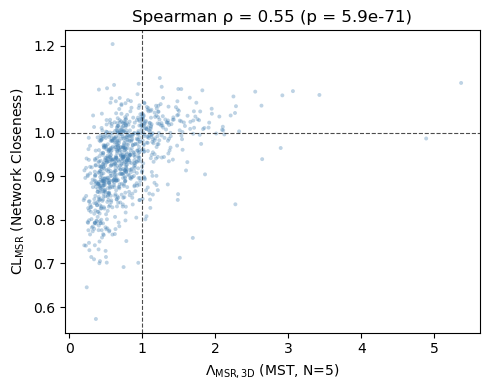

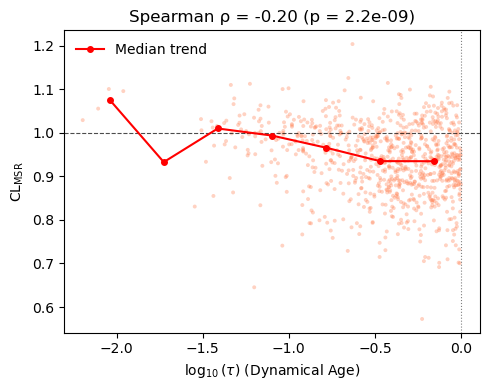

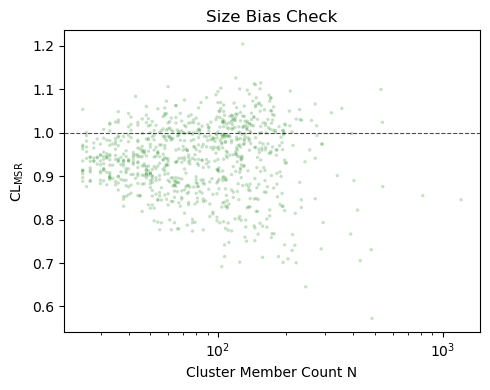

In [5]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata, spearmanr

res = pd.DataFrame(results)

# =====================================================
# 1. 数据完整性与物理范围核查
# =====================================================
print("样本总数:", len(res))
print("N 分布:", res['N'].describe()[['min', '25%', '50%', '75%', 'max']].to_dict())
print("NaN 计数:\n", res[['dc_msr', 'cl_msr', 'bc_msr', 'lambda3d_5', 'tau']].isna().sum())
print("\n物理量范围:")
print(res[['dc_msr', 'cl_msr', 'bc_msr', 'lambda3d_5', 'tau']].describe().loc[['min', '25%', '50%', '75%', 'max']])

# 判定基准：
# MSR 指标 > 1 表示大质量恒星相比普通成员星更具拓扑核心优势（出现质量分层）
# 指标 ≈ 1 表示无分层，< 1 表示反分层

# =====================================================
# 2. 核心图 1：CL_MSR vs Lambda3D_5 (网络拓扑 vs MST 几何)
# =====================================================
sub1 = res.dropna(subset=['cl_msr', 'lambda3d_5'])
rho1, p1 = spearmanr(sub1['cl_msr'], sub1['lambda3d_5'])
print(f"\n[Fig1] Closeness MSR vs Lambda_MSR: rho={rho1:.3f}, p={p1:.2e}, N={len(sub1)}")

plt.figure(figsize=(5, 4))
plt.scatter(sub1['lambda3d_5'], sub1['cl_msr'], s=8, alpha=0.35, c='steelblue', edgecolors='none')
plt.axvline(1.0, ls='--', c='k', lw=0.8, alpha=0.7)
plt.axhline(1.0, ls='--', c='k', lw=0.8, alpha=0.7)
plt.xlabel(r'$\Lambda_{\mathrm{MSR, 3D}}$ (MST, N=5)')
plt.ylabel(r'$\mathrm{CL}_{\mathrm{MSR}}$ (Network Closeness)')
plt.title(f'Spearman ρ = {rho1:.2f} (p = {p1:.1e})')
plt.tight_layout()
plt.savefig('Fig1_CL_vs_Lambda.png', dpi=300)

# =====================================================
# 3. 核心图 2：CL_MSR vs 动力学年龄 tau (质量分层的演化)
# =====================================================
sub2 = res.dropna(subset=['cl_msr', 'tau'])
sub2 = sub2[sub2['tau'] > 0]
log_tau = np.log10(sub2['tau'])

rho2, p2 = spearmanr(log_tau, sub2['cl_msr'])
print(f"[Fig2] Closeness MSR vs log10(tau): rho={rho2:.3f}, p={p2:.2e}, N={len(sub2)}")

plt.figure(figsize=(5, 4))
plt.scatter(log_tau, sub2['cl_msr'], s=8, alpha=0.35, c='coral', edgecolors='none')
plt.axhline(1.0, ls='--', c='k', lw=0.8, alpha=0.7)
plt.axvline(0.0, ls=':', c='gray', lw=0.8) # tau = 1 (已松弛分界线)

# 增加中位数趋势线
bins = np.linspace(log_tau.min(), log_tau.max(), 8)
bin_centers = 0.5 * (bins[:-1] + bins[1:])
medians = [sub2[(log_tau >= bins[i]) & (log_tau < bins[i+1])]['cl_msr'].median() for i in range(len(bins)-1)]
valid = ~np.isnan(medians)
plt.plot(bin_centers[valid], np.array(medians)[valid], 'r-o', lw=1.5, ms=4, label='Median trend')

plt.xlabel(r'$\log_{10}(\tau)$ (Dynamical Age)')
plt.ylabel(r'$\mathrm{CL}_{\mathrm{MSR}}$')
plt.title(f'Spearman ρ = {rho2:.2f} (p = {p2:.1e})')
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig('Fig2_CL_vs_Tau.png', dpi=300)

# =====================================================
# 4. 诊断图 3：CL_MSR 对星团规模 N 的鲁棒性检查
# =====================================================
plt.figure(figsize=(5, 4))
plt.scatter(res['N'], res['cl_msr'], s=6, alpha=0.25, c='forestgreen', edgecolors='none')
plt.axhline(1.0, ls='--', c='k', lw=0.8, alpha=0.7)
plt.xscale('log')
plt.xlabel('Cluster Member Count N')
plt.ylabel(r'$\mathrm{CL}_{\mathrm{MSR}}$')
plt.title('Size Bias Check')
plt.tight_layout()
plt.savefig('Fig3_Size_Bias.png', dpi=300)

# =====================================================
# 5. 偏相关检验：控制恒星数 N 后的独立相关性
# =====================================================
def partial_spearman(x, y, z):
    rx, ry, rz = rankdata(x), rankdata(y), rankdata(z)
    rx_z = rx - np.polyval(np.polyfit(rz, rx, 1), rz)
    ry_z = ry - np.polyval(np.polyfit(rz, ry, 1), rz)
    return spearmanr(rx_z, ry_z)

rho_p1, p_p1 = partial_spearman(sub1['cl_msr'].values, sub1['lambda3d_5'].values, sub1['N'].values)
print(f"\n[偏相关] CL_MSR vs Lambda_MSR | 控制 N: rho={rho_p1:.3f}, p={p_p1:.2e}")

rho_p2, p_p2 = partial_spearman(sub2['cl_msr'].values, log_tau.values, sub2['N'].values)
print(f"[偏相关] CL_MSR vs log10(tau) | 控制 N: rho={rho_p2:.3f}, p={p_p2:.2e}")

[检验 1] CL_MSR 与 Lambda_MSR 的 Spearman 相关系数: rho=0.553 (p=5.88e-71)
[检验 2] 对 log(tau) 的解释力:
         CL_MSR     rho = -0.201
         Lambda_MSR rho = -0.179
[检验 3] 剔除空间紧凑度后，网络拓扑残差与 log(tau) 的相关性: rho=-0.167 (p=6.97e-07)


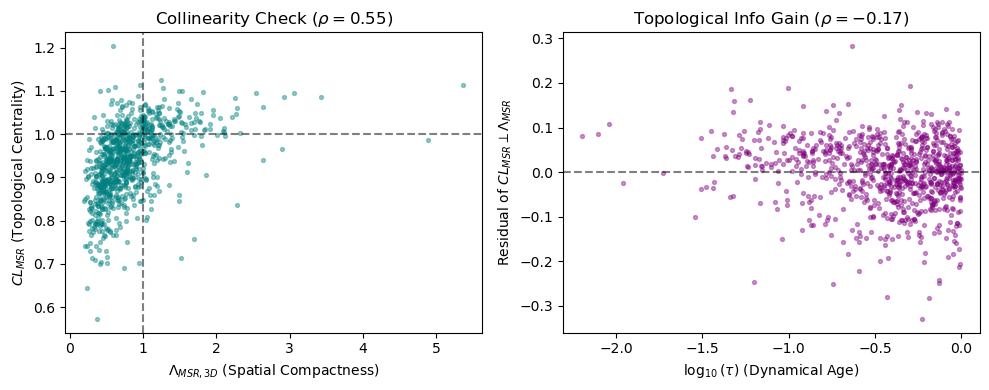

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import statsmodels.api as sm

# 假设 res 已经是上一步跑完的 DataFrame
df_test = res.dropna(subset=['cl_msr', 'lambda3d_5', 'tau']).copy()
df_test = df_test[df_test['tau'] > 0]
df_test['log_tau'] = np.log10(df_test['tau'])

# =====================================================
# 检验 1：共线性检验 (Collinearity Check)
# 目标：证明两者相关但非高度简并。理想 rho 值应在 0.4 到 0.7 之间。
# 如果 rho > 0.9，则说明 $CL_{MSR}$ 完全是 $\Lambda_{MSR}$ 的倒影。
# =====================================================
rho_colin, p_colin = spearmanr(df_test['cl_msr'], df_test['lambda3d_5'])
print(f"[检验 1] CL_MSR 与 Lambda_MSR 的 Spearman 相关系数: rho={rho_colin:.3f} (p={p_colin:.2e})")

# =====================================================
# 检验 2：动力学解释力竞跑 (Predictive Power for Dynamical Age)
# 目标：直接对比谁与动力学年龄 \tau 的相关性更强。
# =====================================================
rho_cl_tau, _ = spearmanr(df_test['cl_msr'], df_test['log_tau'])
rho_lam_tau, _ = spearmanr(df_test['lambda3d_5'], df_test['log_tau'])
print(f"[检验 2] 对 log(tau) 的解释力:")
print(f"         CL_MSR     rho = {rho_cl_tau:.3f}")
print(f"         Lambda_MSR rho = {rho_lam_tau:.3f}")

# =====================================================
# 检验 3：残差信息增益 (Information Gain via Residuals)
# 目标：将 CL_MSR 对 Lambda_MSR 做正交化回归，提取出纯粹属于“网络拓扑”
# 但不包含“空间几何紧凑度”的残差信息。如果这个残差依然与 tau 显著相关，
# 则是回击审稿人最铁的证据：“网络拓扑指标捕捉到了传统 MST 遗漏的动力学演化信息”。
# =====================================================
# 线性回归: CL_MSR = beta * Lambda_MSR + alpha + Residual
X = sm.add_constant(df_test['lambda3d_5'])
Y = df_test['cl_msr']
model = sm.OLS(Y, X).fit()
df_test['cl_residual'] = model.resid

# 检验残差与 tau 的相关性
rho_resid, p_resid = spearmanr(df_test['cl_residual'], df_test['log_tau'])
print(f"[检验 3] 剔除空间紧凑度后，网络拓扑残差与 log(tau) 的相关性: rho={rho_resid:.3f} (p={p_resid:.2e})")

# =====================================================
# 绘图：信息增益直观展示
# =====================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# 图 A：共线性散点图
ax1.scatter(df_test['lambda3d_5'], df_test['cl_msr'], s=8, alpha=0.4, color='teal')
ax1.set_xlabel(r'$\Lambda_{MSR,3D}$ (Spatial Compactness)')
ax1.set_ylabel(r'$CL_{MSR}$ (Topological Centrality)')
ax1.set_title(f'Collinearity Check ($\\rho={rho_colin:.2f}$)')
ax1.axvline(1.0, ls='--', c='k', alpha=0.5)
ax1.axhline(1.0, ls='--', c='k', alpha=0.5)

# 图 B：残差演化图
ax2.scatter(df_test['log_tau'], df_test['cl_residual'], s=8, alpha=0.4, color='purple')
ax2.set_xlabel(r'$\log_{10}(\tau)$ (Dynamical Age)')
ax2.set_ylabel(r'Residual of $CL_{MSR} \perp \Lambda_{MSR}$')
ax2.set_title(f'Topological Info Gain ($\\rho={rho_resid:.2f}$)')
ax2.axhline(0, ls='--', c='k', alpha=0.5)

plt.tight_layout()
plt.show()


In [7]:
X = sm.add_constant(df_test[['lambda3d_5', 'N']])
model = sm.OLS(df_test['cl_msr'], X).fit()
rho_resid2, p_resid2 = spearmanr(model.resid, df_test['log_tau'])
print(f"[偏相关] 控制 N 后，CL_MSR 与 log(tau) 的 Spearman 相关性: rho={rho_resid2:.3f} (p={p_resid2:.2e})")

[偏相关] 控制 N 后，CL_MSR 与 log(tau) 的 Spearman 相关性: rho=-0.191 (p=1.43e-08)


In [8]:
import statsmodels.api as sm
from scipy.stats import spearmanr

# 提取自变量并添加常数项用于 OLS 回归
X = sm.add_constant(df_test['lambda3d_5'])

for metric in ['dc_msr', 'bc_msr']:
    Y = df_test[metric]
    
    # 1. 与传统几何紧凑度的共线性
    rho_colin, p_colin = spearmanr(Y, df_test['lambda3d_5'])
    
    # 2. 对动力学演化 log(tau) 的原始解释力
    rho_tau, p_tau = spearmanr(Y, df_test['log_tau'])
    
    # 3. 剥离空间紧凑度后的网络拓扑残差解释力
    resid = sm.OLS(Y, X).fit().resid
    rho_resid, p_resid = spearmanr(resid, df_test['log_tau'])
    
    print(f"========== {metric.upper()} ==========")
    print(f"[检验1] 与 Lambda_MSR 共线性: rho = {rho_colin: .3f} (p = {p_colin:.2e})")
    print(f"[检验2] 对 log(tau) 解释力   : rho = {rho_tau: .3f} (p = {p_tau:.2e})")
    print(f"[检验3] 拓扑残差相关性       : rho = {rho_resid: .3f} (p = {p_resid:.2e})\n")


========== DC_MSR ==========
[检验1] 与 Lambda_MSR 共线性: rho =  0.481 (p = 1.54e-51)
[检验2] 对 log(tau) 解释力   : rho = -0.139 (p = 3.63e-05)
[检验3] 拓扑残差相关性       : rho = -0.089 (p = 8.68e-03)

========== BC_MSR ==========
[检验1] 与 Lambda_MSR 共线性: rho =  0.352 (p = 9.91e-27)
[检验2] 对 log(tau) 解释力   : rho =  0.038 (p = 2.59e-01)
[检验3] 拓扑残差相关性       : rho =  0.099 (p = 3.41e-03)

